In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from rdflib import Graph, RDF, RDFS, OWL

# 1. Xác định thư mục dự án
PROJECT_DIR = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "data/ACME_Insurance/ontology/insurance.ttl"
        ).exists()
    ),
    None
)

assert PROJECT_DIR is not None, "Không tìm thấy thư mục dự án"

OWL_FILE = (
    PROJECT_DIR / "data/ACME_Insurance/ontology/insurance.ttl"
)

EVAL_DIR = PROJECT_DIR / "results/evaluation"

FIGURE_DIR = (
    PROJECT_DIR / "results/figures/paper_reproduction"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 2. Kiểm tra các file kết quả đã hoàn thành
required_files = [
    "execution_accuracy_all_runs.csv",
    "oea_per_question.csv",
    "aoea_summary.csv",
    "oea_by_quadrant.csv",
    "aoea_by_quadrant.csv"
]

for filename in required_files:
    path = EVAL_DIR / filename
    assert path.exists(), f"Thiếu file: {path}"

# 3. Kiểm tra dữ liệu 50 run
ea = pd.read_csv(
    EVAL_DIR / "execution_accuracy_all_runs.csv"
)

aoea = pd.read_csv(
    EVAL_DIR / "aoea_summary.csv"
)

assert len(ea) == 4300
assert ea["Run"].nunique() == 50
assert set(aoea["Method"]) == {"SQL", "SPARQL"}

# 4. Thiết lập giao diện chung
COLORS = {
    "SQL": "#94A3B8",
    "SPARQL": "#2563EB",
    "TEXT": "#1E293B",
    "GRID": "#E2E8F0",
    "NODE": "#DBEAFE",
    "EDGE": "#64748B"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": COLORS["GRID"],
    "axes.labelcolor": COLORS["TEXT"],
    "text.color": COLORS["TEXT"],
    "xtick.color": COLORS["TEXT"],
    "ytick.color": COLORS["TEXT"],
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.dpi": 300,
    "svg.fonttype": "none"
})

# 5. Hàm xuất PNG và SVG
def save_figure(fig, name):
    fig.savefig(
        FIGURE_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        FIGURE_DIR / f"{name}.svg",
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Saved: {name}.png / {name}.svg")

# 6. Tổng kết
print("=== FIGURE ENVIRONMENT ===")
print("Project:", PROJECT_DIR)
print("Ontology:", OWL_FILE)
print("Runs:", ea["Run"].nunique())
print("Evaluations:", len(ea))

print("\nAOEA (%):")
display(
    aoea.assign(
        AOEA=lambda x: (x["AOEA"] * 100).round(2)
    )
)

print("\nFigure output:", FIGURE_DIR)
print("Environment: OK")

=== FIGURE ENVIRONMENT ===
Project: c:\Users\Win 11 New\Desktop\thuc-nghiem-co-so-httt
Ontology: c:\Users\Win 11 New\Desktop\thuc-nghiem-co-so-httt\data\ACME_Insurance\ontology\insurance.ttl
Runs: 50
Evaluations: 4300

AOEA (%):


,Method,AOEA
0,SPARQL,65.53
1,SQL,45.72



Figure output: c:\Users\Win 11 New\Desktop\thuc-nghiem-co-so-httt\results\figures\paper_reproduction
Environment: OK


In [2]:
# 1. Đọc ontology
ontology = Graph()
ontology.parse(OWL_FILE, format="turtle")

# 2. Lấy danh sách các Class
classes = []

for cls in ontology.subjects(RDF.type, OWL.Class):
    classes.append(str(cls).split("/")[-1])

# 3. Lấy các quan hệ giữa Class
relations = []

for prop in ontology.subjects(RDF.type, OWL.ObjectProperty):
    domain = ontology.value(prop, RDFS.domain)
    range_ = ontology.value(prop, RDFS.range)

    if domain is not None and range_ is not None:
        relations.append((
            str(domain).split("/")[-1],
            str(range_).split("/")[-1],
            str(prop).split("/")[-1]
        ))

# 4. Kiểm tra
print("=== ONTOLOGY SUMMARY ===")
print("Classes:", len(classes))
print("Object Properties:", len(relations))

for source, target, relation in relations:
    print(f"{source} --{relation}--> {target}")

=== ONTOLOGY SUMMARY ===
Classes: 11
Object Properties: 10
Claim --against--> PolicyCoverageDetail
Claim --hasCatastrophe--> Catastrophe
Claim --hasExpensePayment--> ExpensePayment
Claim --hasExpenseReserve--> ExpenseReserve
Claim --hasLossPayment--> LossPayment
Claim --hasLossReserve--> LossReserve
PolicyCoverageDetail --hasPolicy--> Policy
Policy --hasPolicyHolder--> PolicyHolder
PolicyCoverageDetail --hasPremiumAmount--> Premium
Policy --soldByAgent--> Agent


Saved: figure_01.png / figure_01.svg


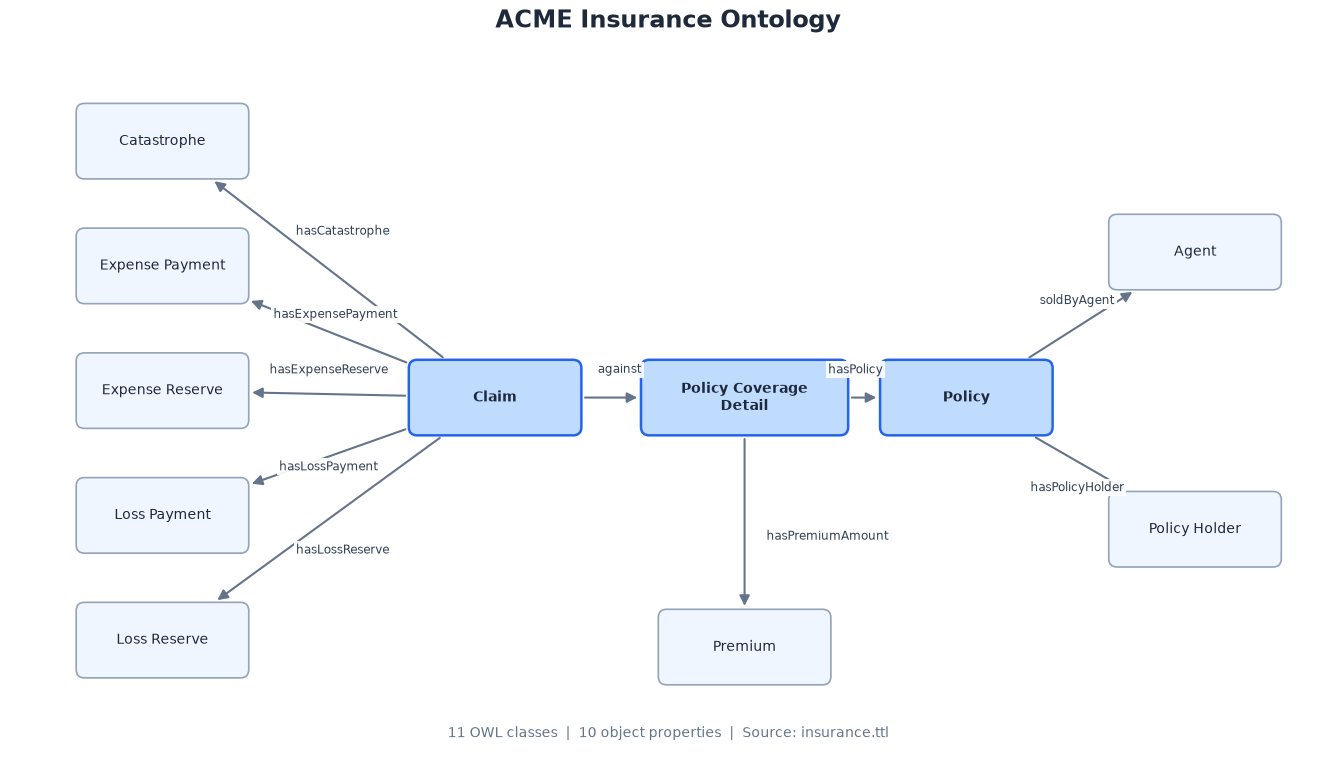

In [4]:

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# 1. Kiểm tra dữ liệu ontology từ Cell 1
assert len(classes) == 11
assert len(relations) == 10

# 2. Tọa độ cố định của 11 class
pos = {
    "Claim": (7.0, 5.9),
    "PolicyCoverageDetail": (10.6, 5.9),
    "Policy": (13.8, 5.9),

    "Catastrophe": (2.2, 9.6),
    "ExpensePayment": (2.2, 7.8),
    "ExpenseReserve": (2.2, 6.0),
    "LossPayment": (2.2, 4.2),
    "LossReserve": (2.2, 2.4),

    "Premium": (10.6, 2.3),
    "Agent": (17.1, 8.0),
    "PolicyHolder": (17.1, 4.0)
}

assert set(classes) == set(pos), (
    "Danh sách class không khớp với ontology"
)

# 3. Vị trí nhãn của 10 quan hệ
label_pos = {
    "against": (8.8, 6.3),
    "hasPolicy": (12.2, 6.3),

    "hasCatastrophe": (4.8, 8.3),
    "hasExpensePayment": (4.7, 7.1),
    "hasExpenseReserve": (4.6, 6.3),
    "hasLossPayment": (4.6, 4.9),
    "hasLossReserve": (4.8, 3.7),

    "hasPremiumAmount": (11.8, 3.9),
    "soldByAgent": (15.4, 7.3),
    "hasPolicyHolder": (15.4, 4.6)
}

assert set(r for _, _, r in relations) == set(label_pos)

# 4. Tạo canvas
fig, ax = plt.subplots(figsize=(18, 9))

ax.set_xlim(0, 19)
ax.set_ylim(0.8, 10.8)
ax.set_aspect("equal")
ax.axis("off")

# 5. Vẽ các class
main_classes = {
    "Claim",
    "PolicyCoverageDetail",
    "Policy"
}

patches = {}

for name, (x, y) in pos.items():
    width = 2.75 if name == "PolicyCoverageDetail" else 2.25
    height = 0.85

    main = name in main_classes

    box = FancyBboxPatch(
        (x - width / 2, y - height / 2),
        width,
        height,
        boxstyle="round,pad=0.12",
        facecolor="#BFDBFE" if main else "#EFF6FF",
        edgecolor="#2563EB" if main else "#94A3B8",
        linewidth=1.8 if main else 1.2,
        zorder=3
    )

    ax.add_patch(box)
    patches[name] = box

    # Xuống dòng với tên class dài
    label = {
        "PolicyCoverageDetail": "Policy Coverage\nDetail",
        "ExpensePayment": "Expense Payment",
        "ExpenseReserve": "Expense Reserve",
        "LossPayment": "Loss Payment",
        "LossReserve": "Loss Reserve",
        "PolicyHolder": "Policy Holder"
    }.get(name, name)

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold" if main else "normal",
        color="#1E293B",
        zorder=5
    )

# 6. Vẽ 10 object property
for source, target, relation in relations:
    arrow = FancyArrowPatch(
        posA=pos[source],
        posB=pos[target],
        patchA=patches[source],
        patchB=patches[target],
        arrowstyle="-|>",
        mutation_scale=15,
        linewidth=1.5,
        color="#64748B",
        connectionstyle="arc3,rad=0",
        zorder=2
    )

    ax.add_patch(arrow)

    lx, ly = label_pos[relation]

    ax.text(
        lx, ly, relation,
        ha="center",
        va="center",
        fontsize=8.5,
        color="#334155",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.92,
            pad=1.5
        ),
        zorder=4
    )

# 7. Tiêu đề và chú thích
ax.set_title(
    "ACME Insurance Ontology",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.text(
    9.5, 1.0,
    "11 OWL classes  |  10 object properties  |  Source: insurance.ttl",
    ha="center",
    fontsize=10,
    color="#64748B"
)

# 8. Xuất hình
save_figure(fig, "figure_01")

plt.show()
plt.close(fig)

Saved: figure_02.png / figure_02.svg


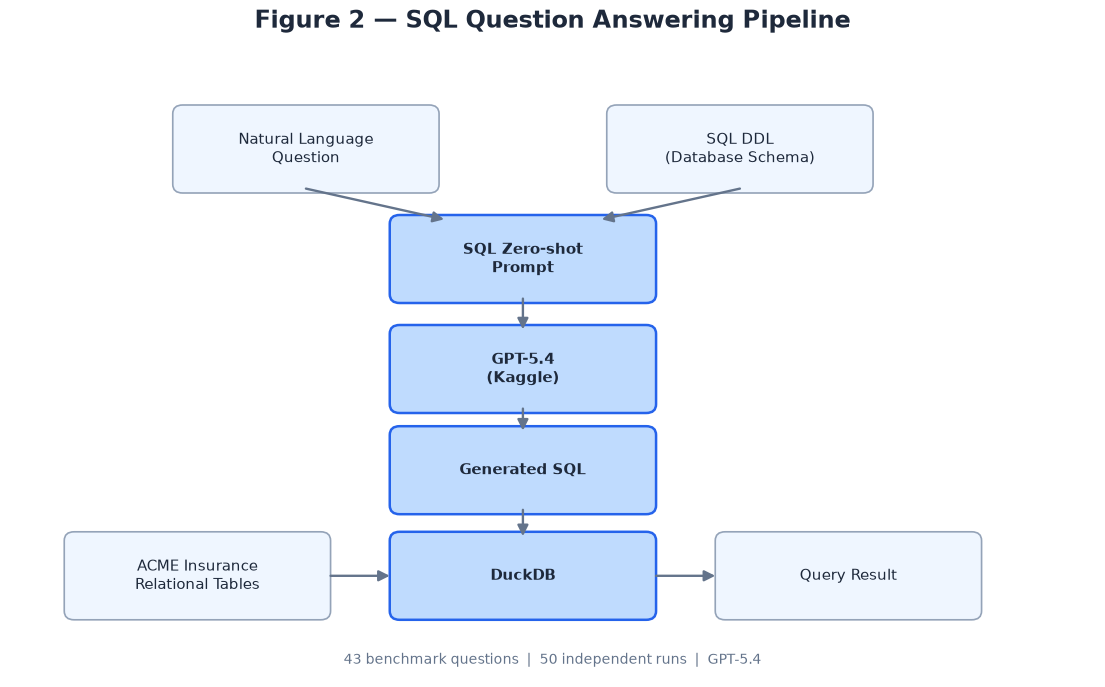

In [5]:

from matplotlib.patches import FancyBboxPatch

# 1. Tạo canvas
fig, ax = plt.subplots(figsize=(14, 8))

ax.set_xlim(0, 11)
ax.set_ylim(0.5, 7.5)
ax.axis("off")

# 2. Hàm vẽ thành phần
def draw_box(x, y, label, width=2.5, height=0.8,
             main=False):
    box = FancyBboxPatch(
        (x - width / 2, y - height / 2),
        width, height,
        boxstyle="round,pad=0.1",
        facecolor="#BFDBFE" if main else "#EFF6FF",
        edgecolor="#2563EB" if main else "#94A3B8",
        linewidth=1.8 if main else 1.2
    )
    ax.add_patch(box)

    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=11,
        fontweight="bold" if main else "normal",
        color="#1E293B"
    )

# 3. Hàm vẽ mũi tên
def draw_arrow(start, end):
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(
            arrowstyle="-|>",
            lw=1.7,
            color="#64748B",
            mutation_scale=16,
            shrinkA=0,
            shrinkB=0
        )
    )

# 4. Các thành phần pipeline
draw_box(3.0, 6.5, "Natural Language\nQuestion")
draw_box(7.4, 6.5, "SQL DDL\n(Database Schema)")

draw_box(5.2, 5.25, "SQL Zero-shot\nPrompt", main=True)
draw_box(5.2, 4.0, "GPT-5.4\n(Kaggle)", main=True)
draw_box(5.2, 2.85, "Generated SQL", main=True)

draw_box(1.9, 1.65, "ACME Insurance\nRelational Tables")
draw_box(5.2, 1.65, "DuckDB", main=True)
draw_box(8.5, 1.65, "Query Result")

# 5. Luồng tạo SQL
draw_arrow((3.0, 6.05), (4.4, 5.70))
draw_arrow((7.4, 6.05), (6.0, 5.70))

draw_arrow((5.2, 4.80), (5.2, 4.45))
draw_arrow((5.2, 3.55), (5.2, 3.30))
draw_arrow((5.2, 2.40), (5.2, 2.10))

# 6. Dữ liệu nguồn và kết quả
draw_arrow((3.25, 1.65), (3.85, 1.65))
draw_arrow((6.55, 1.65), (7.15, 1.65))

# 7. Tiêu đề
ax.set_title(
    "Figure 2 — SQL Question Answering Pipeline",
    fontsize=17,
    fontweight="bold",
    pad=24
)

ax.text(
    5.5, 0.65,
    "43 benchmark questions  |  50 independent runs  |  GPT-5.4",
    ha="center",
    fontsize=10,
    color="#64748B"
)

# 8. Xuất hình
save_figure(fig, "figure_02")

plt.show()
plt.close(fig)

Saved: figure_03.png / figure_03.svg


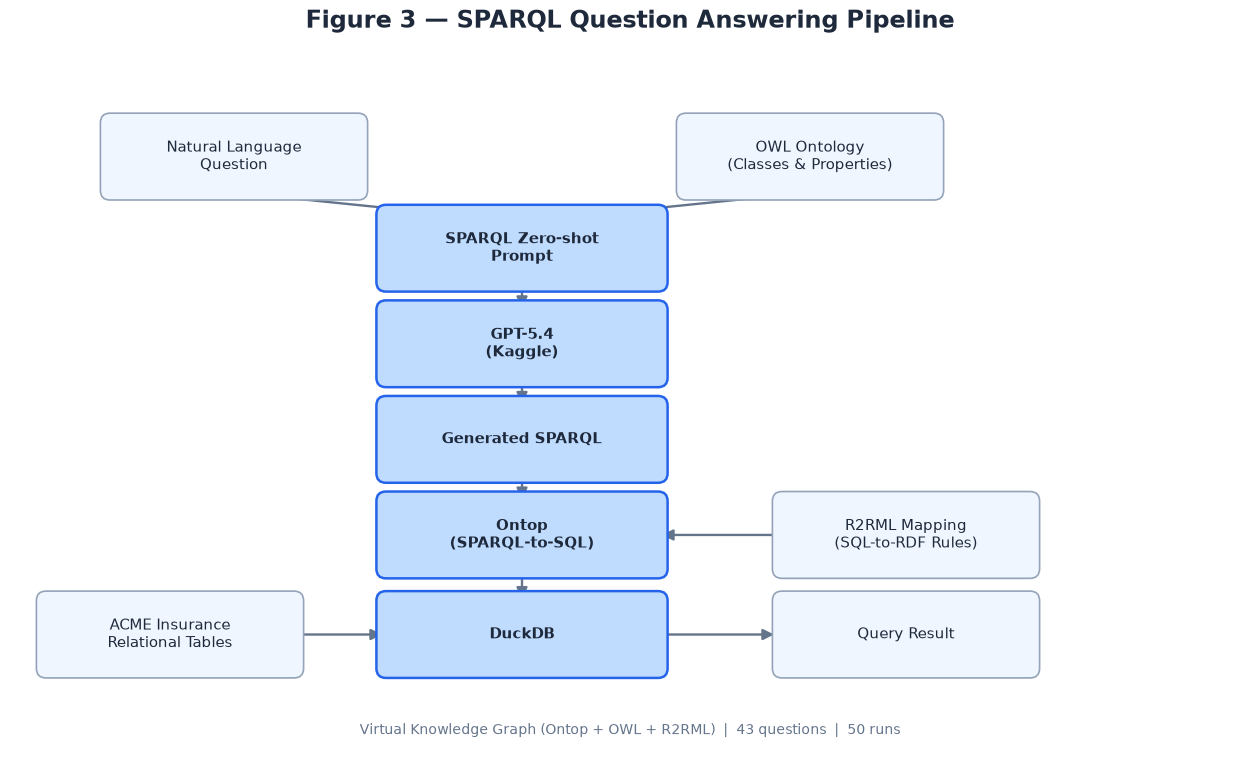

In [6]:
from matplotlib.patches import FancyBboxPatch

# 1. Tạo canvas
fig, ax = plt.subplots(figsize=(16, 9))

ax.set_xlim(0, 15.5)
ax.set_ylim(0.3, 9.0)
ax.axis("off")

# 2. Hàm vẽ thành phần
def draw_kg_box(x, y, label, width=3.1, height=0.85,
                main=False):
    box = FancyBboxPatch(
        (x - width / 2, y - height / 2),
        width,
        height,
        boxstyle="round,pad=0.12",
        facecolor="#BFDBFE" if main else "#EFF6FF",
        edgecolor="#2563EB" if main else "#94A3B8",
        linewidth=1.8 if main else 1.2,
        zorder=3
    )

    ax.add_patch(box)

    ax.text(
        x, y, label,
        ha="center",
        va="center",
        fontsize=10.5,
        fontweight="bold" if main else "normal",
        color="#1E293B",
        zorder=4
    )


def draw_kg_arrow(start, end):
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(
            arrowstyle="-|>",
            lw=1.7,
            color="#64748B",
            mutation_scale=16,
            shrinkA=0,
            shrinkB=0
        ),
        zorder=2
    )


# 3. Thành phần sinh SPARQL
draw_kg_box(
    2.8, 7.8,
    "Natural Language\nQuestion"
)

draw_kg_box(
    10.0, 7.8,
    "OWL Ontology\n(Classes & Properties)"
)

draw_kg_box(
    6.4, 6.65,
    "SPARQL Zero-shot\nPrompt",
    width=3.4,
    main=True
)

draw_kg_box(
    6.4, 5.45,
    "GPT-5.4\n(Kaggle)",
    width=3.4,
    main=True
)

draw_kg_box(
    6.4, 4.25,
    "Generated SPARQL",
    width=3.4,
    main=True
)

# 4. Thành phần Virtual Knowledge Graph
draw_kg_box(
    6.4, 3.05,
    "Ontop\n(SPARQL-to-SQL)",
    width=3.4,
    main=True
)

draw_kg_box(
    11.2, 3.05,
    "R2RML Mapping\n(SQL-to-RDF Rules)"
)

draw_kg_box(
    2.0, 1.8,
    "ACME Insurance\nRelational Tables"
)

draw_kg_box(
    6.4, 1.8,
    "DuckDB",
    width=3.4,
    main=True
)

draw_kg_box(
    11.2, 1.8,
    "Query Result"
)

# 5. Đường đi của câu hỏi và ontology
draw_kg_arrow(
    (2.8, 7.35),
    (5.25, 7.10)
)

draw_kg_arrow(
    (10.0, 7.35),
    (7.55, 7.10)
)

# 6. Luồng sinh SPARQL
draw_kg_arrow(
    (6.4, 6.10),
    (6.4, 5.90)
)

draw_kg_arrow(
    (6.4, 5.00),
    (6.4, 4.70)
)

draw_kg_arrow(
    (6.4, 3.80),
    (6.4, 3.50)
)

# 7. Mapping cung cấp cho Ontop
draw_kg_arrow(
    (9.55, 3.05),
    (8.15, 3.05)
)

# 8. Ontop thực thi SQL qua DuckDB
draw_kg_arrow(
    (6.4, 2.60),
    (6.4, 2.25)
)

draw_kg_arrow(
    (3.65, 1.8),
    (4.65, 1.8)
)

draw_kg_arrow(
    (8.15, 1.8),
    (9.55, 1.8)
)

# 9. Tiêu đề
ax.set_title(
    "Figure 3 — SPARQL Question Answering Pipeline",
    fontsize=17,
    fontweight="bold",
    pad=24
)

ax.text(
    7.75, 0.55,
    "Virtual Knowledge Graph (Ontop + OWL + R2RML)"
    "  |  43 questions  |  50 runs",
    ha="center",
    fontsize=10,
    color="#64748B"
)

# 10. Xuất hình
save_figure(fig, "figure_03")

plt.show()
plt.close(fig)


Saved: figure_04.png / figure_04.svg


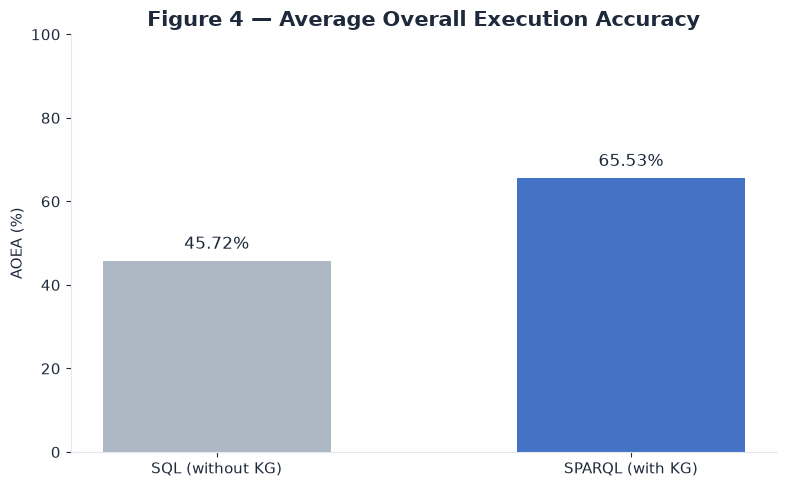

SQL AOEA: 45.72%
SPARQL AOEA: 65.53%


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Đọc kết quả AOEA từ 50 run
aoea = pd.read_csv(
    EVAL_DIR / "aoea_summary.csv"
).set_index("Method")

methods = ["SQL", "SPARQL"]
scores = aoea.loc[methods, "AOEA"] * 100

assert len(scores) == 2
assert scores.between(0, 100).all()

# 2. Vẽ Figure 4 theo bố cục gốc
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["SQL (without KG)", "SPARQL (with KG)"],
    scores,
    color=["#AEB7C4", "#4472C4"],
    width=0.55
)

ax.set_ylim(0, 100)
ax.set_ylabel("AOEA (%)")
ax.set_title(
    "Figure 4 — Average Overall Execution Accuracy",
    fontsize=15
)

# 3. Hiển thị giá trị trên mỗi cột
for bar, score in zip(bars, scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        score + 2,
        f"{score:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12
    )

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

# 4. Xuất hình
save_figure(fig, "figure_04")

plt.show()
plt.close(fig)

# 5. Kiểm tra số liệu
print("SQL AOEA:", f"{scores['SQL']:.2f}%")
print("SPARQL AOEA:", f"{scores['SPARQL']:.2f}%")

Saved: figure_05.png / figure_05.svg


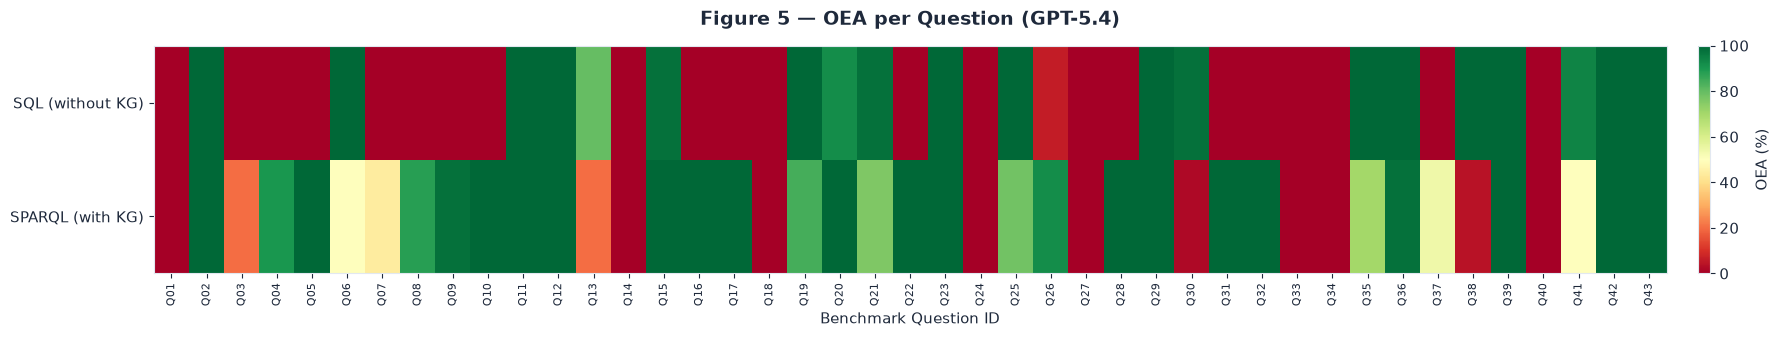

Figure 5 completed.
Methods: 2
Questions: 43
OEA range: 0.0 to 1.0


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Đọc OEA của 43 câu hỏi
oea = pd.read_csv(
    EVAL_DIR / "oea_per_question.csv"
)

oea["ID"] = oea["ID"].astype(int)

assert len(oea) == 86
assert not oea.duplicated(["ID", "Method"]).any()
assert oea["OEA"].between(0, 1).all()

# 2. Chuyển thành bảng: 2 phương pháp × 43 câu hỏi
heatmap = oea.pivot(
    index="Method",
    columns="ID",
    values="OEA"
).loc[["SQL", "SPARQL"], range(1, 44)]

assert heatmap.shape == (2, 43)
assert not heatmap.isna().any().any()

# 3. Vẽ heatmap theo bố cục notebook gốc
fig, ax = plt.subplots(figsize=(18, 3.5))

im = ax.imshow(
    heatmap.values,
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_yticks([0, 1])
ax.set_yticklabels([
    "SQL (without KG)",
    "SPARQL (with KG)"
])

ax.set_xticks(range(43))
ax.set_xticklabels(
    [f"Q{i:02d}" for i in range(1, 44)],
    rotation=90,
    fontsize=8
)

ax.set_xlabel("Benchmark Question ID")
ax.set_title(
    "Figure 5 — OEA per Question (GPT-5.4)",
    pad=15
)

# 4. Thanh màu từ 0% đến 100%
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.025,
    pad=0.02
)

cbar.set_label("OEA (%)")
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1])
cbar.set_ticklabels([
    "0", "20", "40", "60", "80", "100"
])

plt.tight_layout()

# 5. Xuất hình PNG và SVG
save_figure(fig, "figure_05")

plt.show()
plt.close(fig)

print("Figure 5 completed.")
print("Methods:", heatmap.shape[0])
print("Questions:", heatmap.shape[1])
print("OEA range:", heatmap.values.min(), "to", heatmap.values.max())

Saved: figure_06.png / figure_06.svg


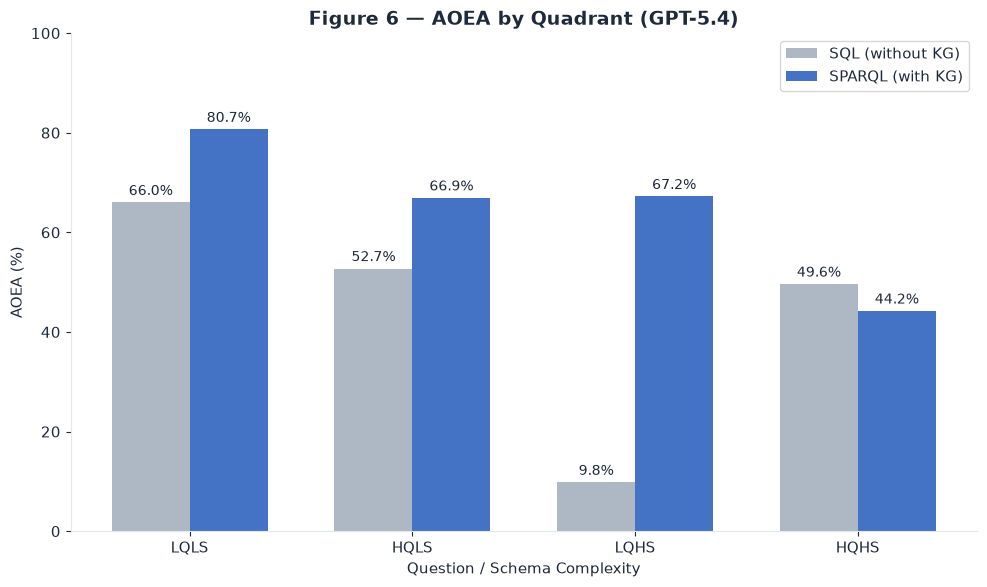

=== AOEA BY QUADRANT (%) ===


Method,SQL,SPARQL
Quadrant,,
LQLS,66.00,80.67
HQLS,52.73,66.91
LQHS,9.80,67.20
HQHS,49.60,44.20


Figure 6 completed.


In [11]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu AOEA theo Quadrant
df = pd.read_csv(
    EVAL_DIR / "aoea_by_quadrant.csv"
)

quadrants = ["LQLS", "HQLS", "LQHS", "HQHS"]

assert len(df) == 8
assert not df.duplicated(["Quadrant", "Method"]).any()
assert set(df["Quadrant"]) == set(quadrants)
assert set(df["Method"]) == {"SQL", "SPARQL"}
assert df["AOEA"].between(0, 1).all()

table = df.pivot(
    index="Quadrant",
    columns="Method",
    values="AOEA"
).loc[quadrants, ["SQL", "SPARQL"]] * 100

assert not table.isna().any().any()

# 2. Vẽ biểu đồ theo notebook gốc
fig, ax = plt.subplots(figsize=(10, 6))

x = range(len(quadrants))
width = 0.35

sql_bars = ax.bar(
    [i - width / 2 for i in x],
    table["SQL"],
    width,
    label="SQL (without KG)",
    color="#AEB7C4"
)

sparql_bars = ax.bar(
    [i + width / 2 for i in x],
    table["SPARQL"],
    width,
    label="SPARQL (with KG)",
    color="#4472C4"
)

# 3. Nhãn và định dạng
ax.set_xticks(list(x))
ax.set_xticklabels(quadrants)

ax.set_ylim(0, 100)
ax.set_ylabel("AOEA (%)")
ax.set_xlabel("Question / Schema Complexity")

ax.set_title(
    "Figure 6 — AOEA by Quadrant (GPT-5.4)"
)

ax.legend()

# 4. Hiển thị AOEA trên từng cột
for bars in [sql_bars, sparql_bars]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 1.5,
            f"{value:.1f}%",
            ha="center",
            fontsize=10
        )

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

# 5. Xuất hình PNG và SVG
save_figure(fig, "figure_06")

plt.show()
plt.close(fig)

# 6. Kiểm tra kết quả
print("=== AOEA BY QUADRANT (%) ===")
display(table.round(2))

print("Figure 6 completed.")

Saved: figure_07.png / figure_07.svg


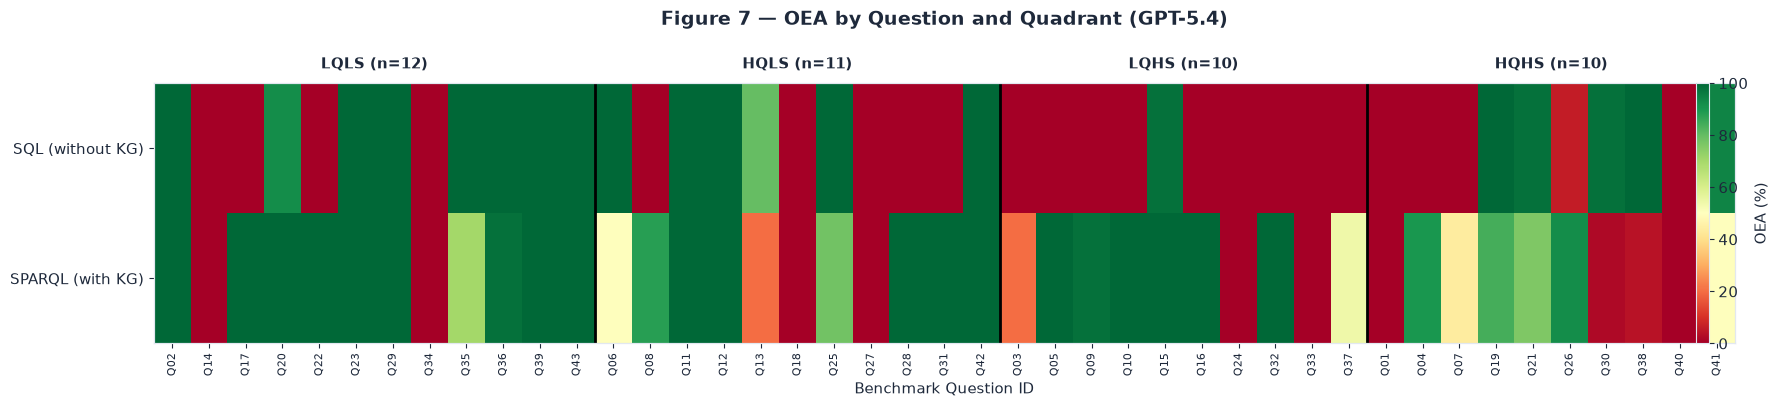

Figure 7 completed.
Questions: 43
Methods: 2

Question distribution:
LQLS: 12
HQLS: 11
LQHS: 10
HQHS: 10


In [12]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Đọc OEA và nhãn Quadrant
df = pd.read_csv(
    EVAL_DIR / "oea_by_quadrant.csv"
)

df["ID"] = df["ID"].astype(int)

groups = ["LQLS", "HQLS", "LQHS", "HQHS"]

assert len(df) == 86
assert not df.duplicated(["ID", "Method"]).any()
assert set(df["Method"]) == {"SQL", "SPARQL"}
assert set(df["Quadrant"]) == set(groups)
assert df["OEA"].between(0, 1).all()

# 2. Sắp xếp câu hỏi theo Quadrant
questions = df[["ID", "Quadrant"]].drop_duplicates()

assert len(questions) == 43
assert questions["ID"].is_unique
assert set(questions["ID"]) == set(range(1, 44))

ordered_ids = []
centers = []
group_labels = []
boundaries = []

for group in groups:
    ids = sorted(
        questions.loc[
            questions["Quadrant"] == group, "ID"
        ].tolist()
    )

    start = len(ordered_ids)
    ordered_ids.extend(ids)

    centers.append(start + (len(ids) - 1) / 2)
    group_labels.append(f"{group} (n={len(ids)})")
    boundaries.append(len(ordered_ids) - 0.5)

assert len(ordered_ids) == 43
assert len(set(ordered_ids)) == 43

# 3. Tạo ma trận OEA
heatmap = df.pivot(
    index="Method",
    columns="ID",
    values="OEA"
).loc[["SQL", "SPARQL"], ordered_ids]

assert heatmap.shape == (2, 43)
assert not heatmap.isna().any().any()

# 4. Vẽ heatmap theo notebook gốc
fig, ax = plt.subplots(figsize=(18, 4.2))

im = ax.imshow(
    heatmap.values,
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_yticks([0, 1])
ax.set_yticklabels([
    "SQL (without KG)",
    "SPARQL (with KG)"
])

ax.set_xticks(range(43))
ax.set_xticklabels(
    [f"Q{i:02d}" for i in ordered_ids],
    rotation=90,
    fontsize=8
)

# 5. Đường phân cách giữa các Quadrant
for boundary in boundaries[:-1]:
    ax.axvline(
        boundary,
        color="black",
        linewidth=2
    )

# Hiển thị tên Quadrant phía trên
top = ax.twiny()
top.set_xlim(ax.get_xlim())
top.set_xticks(centers)
top.set_xticklabels(
    group_labels,
    fontsize=11,
    fontweight="bold"
)
top.tick_params(axis="x", length=0, pad=8)

ax.set_xlabel("Benchmark Question ID")
ax.set_title(
    "Figure 7 — OEA by Question and Quadrant (GPT-5.4)",
    pad=42
)

# 6. Thanh màu OEA
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.025,
    pad=0.02
)

cbar.set_label("OEA (%)")
cbar.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1])
cbar.set_ticklabels([
    "0", "20", "40", "60", "80", "100"
])

plt.tight_layout()

# 7. Xuất hình
save_figure(fig, "figure_07")

plt.show()
plt.close(fig)

# 8. Kiểm tra
print("Figure 7 completed.")
print("Questions:", len(ordered_ids))
print("Methods:", heatmap.shape[0])

print("\nQuestion distribution:")
for group in groups:
    count = (questions["Quadrant"] == group).sum()
    print(f"{group}: {count}")